# 05 · Curves as waves: does the rhythm of a curve tell the kinds apart, and does a burst change it?

**What a Fourier transform does.** A curve (one value per word) is rewritten as a sum of waves of different speeds.
Its **spectrum** says how much of each speed the curve holds: slow waves are long trends (a signal staying high for
a paragraph), fast waves are word-to-word jitter. The curve says *what happened at each word*; the spectrum says
*how the curve moves*.

**Whole texts first.** Texts have 169–330 measured words, so every curve is **stretched** to 256 points (straight
lines between neighbouring values) to give spectra of the same length (128 speeds). The 0-speed term is left out:
it is just the sum of the values, not a wave. Then, as agreed:
1. **Human texts** (learnt from, as in notebook 04): cluster the spectra (k-medoids, k = 2, as notebook 02), label
   each text from the other 24 by its nearest spectrum (1-NN), and with two Fourier-based classifiers that look at
   the rhythm of short windows (**BOSSVS** and **WEASEL**, from `pyts`, fixed settings).
2. **Qwen's texts** (only labelled): does a hot burst change the whole text's spectrum?
3. **Only if it does: where?** The spectrum of short windows sliding along the text.

Runtime: ~15 minutes (the Fourier classifiers are re-learnt 25 times per signal), no model run.

In [1]:
import os
import sys
import warnings
from pathlib import Path

os.environ.setdefault("HF_HUB_OFFLINE", "1")
warnings.filterwarnings("ignore")
QWEN7B_DIR = Path.cwd()
for folder in [Path.cwd(), *Path.cwd().parents]:
    if (folder / "config/qwen_config.py").exists():
        QWEN7B_DIR = folder / "src/note_books/Qwen7B"
        break
sys.path.insert(0, str(QWEN7B_DIR))

import analysis
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from scipy.spatial.distance import cdist

from analysis.classify import leave_one_out
from analysis.cluster import k_medoids, score
from analysis.evolving import first_row_from_char
from analysis.figures import (plot_bursts_stacked, plot_curve_and_spectrum, plot_fast_share, plot_summary,
                              save_to)
from analysis.fourier import (bossvs_labels, bossvs_leave_one_out, fast_share, spectrum, weasel_leave_one_out,
                              window_energy)
from analysis.signals import (SIGNALS, curve_with_rows, curves_of, dataset_names, kinds_of, load_tables,
                              signal_by_key)
from config.qwen_config import (BURST_DIR, BURST_TOKENS_DIR, BURST_WORDS_DIR, EVOLVING_SIGNALS, FOURIER_FIGURES_DIR,
                         FOURIER_TABLES_DIR, FOURIER_WINDOWS, MODEL_NAME)

for folder in [FOURIER_FIGURES_DIR, FOURIER_TABLES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)
pd.set_option("display.width", 200)

real_names = dataset_names()
real_kinds = list(kinds_of(real_names))
real_words, real_tokens = load_tables(real_names, MODEL_NAME)
bursts = pd.read_csv(BURST_DIR / "bursts.csv")
burst_names = list(bursts["text"])
clean_names = list(bursts["clean original"])
burst_words, burst_tokens = load_tables(burst_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)
clean_words, clean_tokens = load_tables(clean_names, MODEL_NAME, BURST_WORDS_DIR, BURST_TOKENS_DIR)

**An example**: the surprisal curve of the clean Paris text and of its burst copy, and their spectra.

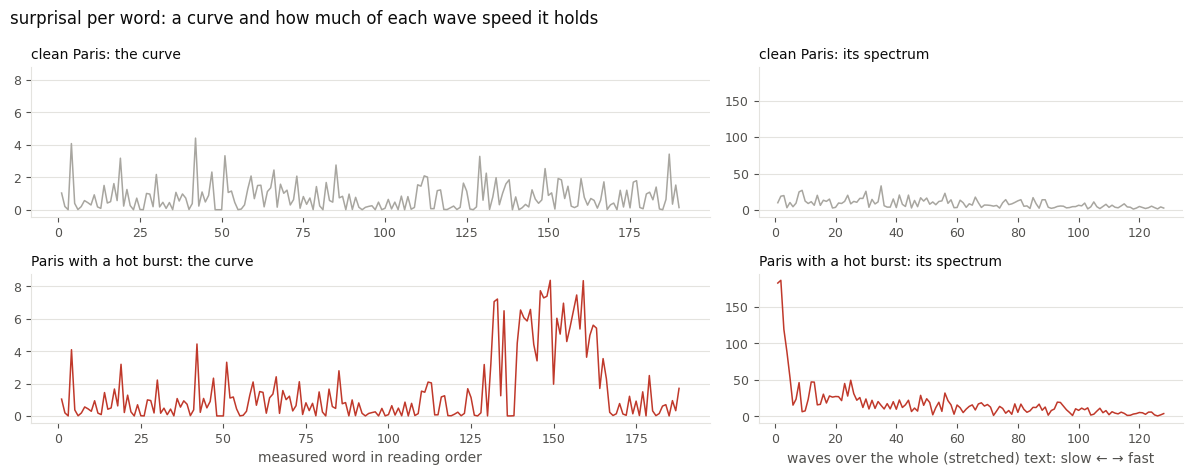

In [2]:
surprisal = signal_by_key("surprisal_per_word")
clean_curve = curves_of(surprisal, ["factual_clean_paris"], clean_words, clean_tokens)[0]
burst_curve = curves_of(surprisal, ["factual_burst_paris"], burst_words, burst_tokens)[0]
fig = plot_curve_and_spectrum(surprisal.name, [("clean Paris", clean_curve, spectrum(clean_curve), "#a8a6a0"),
                                               ("Paris with a hot burst", burst_curve, spectrum(burst_curve),
                                                "#c0392b")])
save_to(fig, FOURIER_FIGURES_DIR, "example_curve_and_spectrum.png")
plt.show()

## 1. Human texts: do the spectra tell factual from creative? (every signal)
Per signal, out of 25: texts in their own kind's cluster when the spectra are clustered; and texts labelled right
when each is labelled from the other 24 by 1-NN on spectra, by BOSSVS and by WEASEL. For comparison, the last
column is 1-NN with DTW on the raw curves (notebook 04).

,method,best signal,right (of 25)
0,spectra clustered,"Qwen-embedding distance, top 1 vs real word, o...",21
1,1-NN on spectra,"LCA height, likely guesses, at most 3 (10%)",21
2,BOSSVS,"LCA height, top 3 guesses",23
3,WEASEL,"LCA height, likely guesses, at most 3 (5%)",15
4,1-NN DTW (notebook 04),"GloVe distance, top 1 vs real word",22


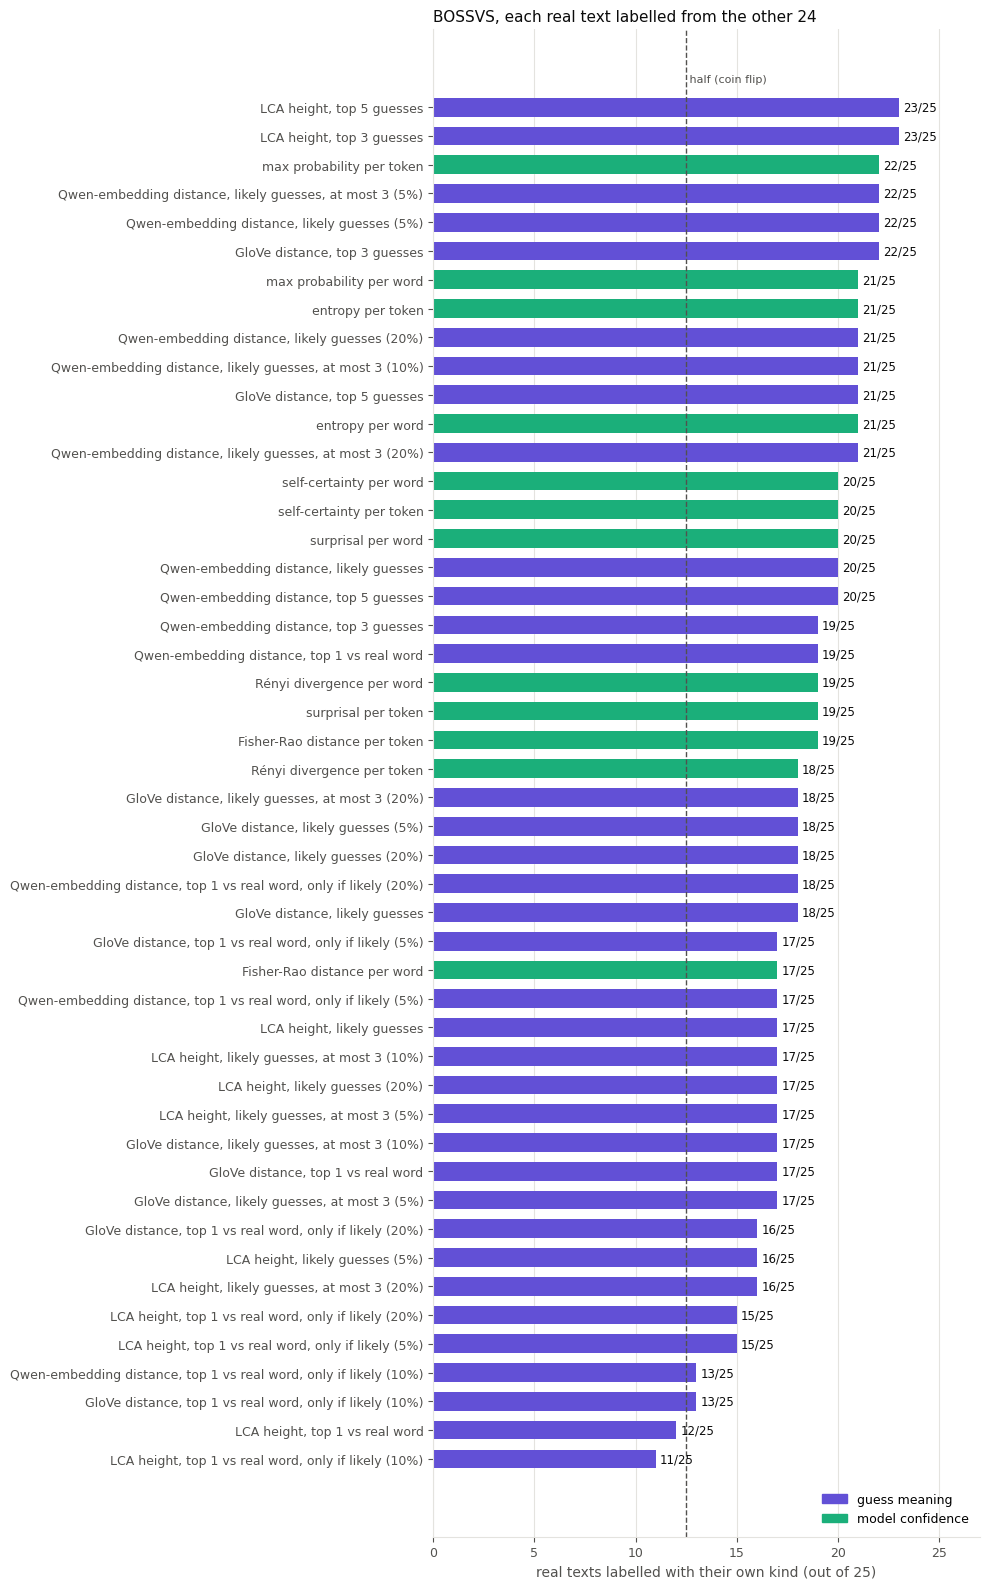

,signal,name,spectra clustered,1-NN on spectra,BOSSVS,WEASEL,1-NN DTW (notebook 04)
6,glove_top5,"GloVe distance, top 5 guesses",19,19,21,11,20
15,lca_likely_top3_10pct,"LCA height, likely guesses, at most 3 (10%)",13,21,17,12,20
36,surprisal_per_word,surprisal per word,16,15,20,12,22


In [3]:
dtw_scores = pd.read_csv(QWEN7B_DIR / "results/classify/tables/leave_one_out.csv").set_index("signal")["correct"]
method_rows = []
for signal in SIGNALS:
    curves = curves_of(signal, real_names, real_words, real_tokens)
    spectra = []
    for curve in curves:
        spectra.append(spectrum(curve))
    table = cdist(np.array(spectra), np.array(spectra))       # Euclidean distance between spectra
    labels, _centres = k_medoids(table)
    nn_given, _nearest = leave_one_out(table, real_kinds)
    boss_given = bossvs_leave_one_out(curves, real_kinds)
    weasel_given = weasel_leave_one_out(curves, real_kinds)
    row = {"signal": signal.key, "name": signal.name, "family": signal.family, "texts": len(real_names),
           "spectra clustered": score(real_names, real_kinds, labels)["correct"]}
    for method, given in [("1-NN on spectra", nn_given), ("BOSSVS", boss_given), ("WEASEL", weasel_given)]:
        right = 0
        for index in range(len(real_names)):
            if given[index] == real_kinds[index]:
                right += 1
        row[method] = right
    row["1-NN DTW (notebook 04)"] = int(dtw_scores[signal.key])
    method_rows.append(row)
methods = pd.DataFrame(method_rows)
methods.to_csv(FOURIER_TABLES_DIR / "human_texts.csv", index=False)

best_rows = []
for method in ["spectra clustered", "1-NN on spectra", "BOSSVS", "WEASEL", "1-NN DTW (notebook 04)"]:
    best = methods.sort_values(method, ascending=False).iloc[0]
    best_rows.append({"method": method, "best signal": best["name"], "right (of 25)": best[method]})
display(pd.DataFrame(best_rows))

boss = methods.rename(columns={"BOSSVS": "correct"})
fig = plot_summary(boss, title="BOSSVS, each real text labelled from the other 24",
                   xlabel="real texts labelled with their own kind (out of 25)")
save_to(fig, FOURIER_FIGURES_DIR, "bossvs_leave_one_out.png")
plt.show()
display(methods[methods["signal"].isin(EVOLVING_SIGNALS)].drop(columns=["family", "texts"]))

## 2. Qwen's texts: does a hot burst change the whole text's spectrum?
For the three signals of notebook 03, per clean and burst text: the BOSSVS label (learnt from all 25 real texts),
the distance from its spectrum to the nearest real text's spectrum, and the **fast share** (the share of the
spectrum's energy in the faster half of the speeds). A burst text is **flagged** when its fast share is lower than
its clean original's: the burst then added slow waves (a long rise and fall) to the text.

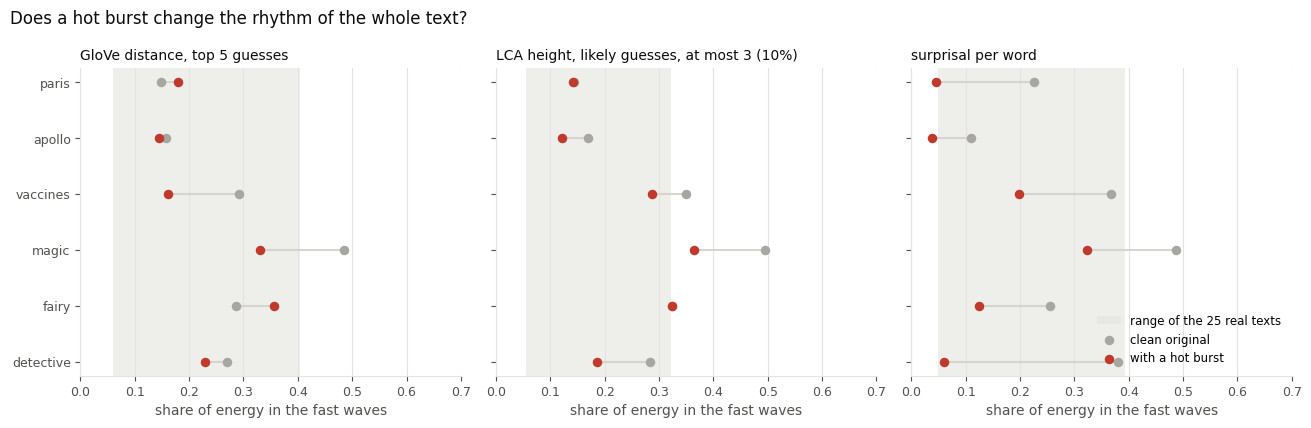

,signal,text,"BOSSVS, clean","BOSSVS, burst","to nearest real spectrum, clean","to nearest real spectrum, burst","fast share, clean","fast share, burst",fast share drops
0,"GloVe distance, top 5 guesses",factual_paris,creative,creative,7.610,7.510,0.148,0.179,False
1,"GloVe distance, top 5 guesses",factual_apollo,creative,factual,8.074,7.902,0.157,0.145,True
2,"GloVe distance, top 5 guesses",factual_vaccines,creative,creative,7.712,8.479,0.292,0.161,True
3,"GloVe distance, top 5 guesses",creative_magic,creative,factual,14.603,8.993,0.485,0.330,True
4,"GloVe distance, top 5 guesses",creative_fairy,factual,factual,9.420,9.020,0.287,0.356,False
5,"GloVe distance, top 5 guesses",creative_detective,factual,factual,8.343,8.320,0.270,0.229,True
6,"LCA height, likely guesses, at most 3 (10%)",factual_paris,factual,factual,223.743,219.831,0.144,0.142,True
7,"LCA height, likely guesses, at most 3 (10%)",factual_apollo,factual,factual,226.104,260.693,0.170,0.121,True
8,"LCA height, likely guesses, at most 3 (10%)",factual_vaccines,factual,factual,216.385,217.618,0.349,0.287,True
9,"LCA height, likely guesses, at most 3 (10%)",creative_magic,creative,creative,274.885,218.745,0.496,0.365,True


signal
GloVe distance, top 5 guesses                  4
LCA height, likely guesses, at most 3 (10%)    5
surprisal per word                             6
Name: burst texts whose fast share drops (of 6), dtype: int64

In [4]:
generated_names = clean_names + burst_names
generated_words = {**clean_words, **burst_words}
generated_tokens = {**clean_tokens, **burst_tokens}
whole_rows = []
real_ranges = {}
for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    real_curves = curves_of(signal, real_names, real_words, real_tokens)
    real_spectra = np.array([spectrum(curve) for curve in real_curves])
    real_shares = [fast_share(values) for values in real_spectra]
    real_ranges[signal.name] = (min(real_shares), max(real_shares))
    generated_curves = curves_of(signal, generated_names, generated_words, generated_tokens)
    generated_spectra = np.array([spectrum(curve) for curve in generated_curves])
    to_real = cdist(generated_spectra, real_spectra).min(axis=1)
    labels = bossvs_labels(real_curves, real_kinds, generated_curves)
    for index in range(len(clean_names)):
        clean_index, burst_index = index, index + len(clean_names)
        whole_rows.append({"signal": signal.name, "text": clean_names[index].replace("_clean", ""),
                           "BOSSVS, clean": labels[clean_index], "BOSSVS, burst": labels[burst_index],
                           "to nearest real spectrum, clean": to_real[clean_index],
                           "to nearest real spectrum, burst": to_real[burst_index],
                           "fast share, clean": fast_share(generated_spectra[clean_index]),
                           "fast share, burst": fast_share(generated_spectra[burst_index])})
whole = pd.DataFrame(whole_rows)
whole["fast share drops"] = whole["fast share, burst"] < whole["fast share, clean"]
whole.to_csv(FOURIER_TABLES_DIR / "burst_whole_texts.csv", index=False)

fig = plot_fast_share(whole, real_ranges)
save_to(fig, FOURIER_FIGURES_DIR, "fast_share.png")
plt.show()
display(whole.round(3))
display(whole.groupby("signal", sort=False)["fast share drops"].sum().rename("burst texts whose fast share drops (of 6)"))

## 3. Where? The spectrum of short windows
For each burst text: at every word, the total spectral energy of the `window` words around it (16 or 32 words),
for the burst text and for its clean original. By Parseval's theorem this energy equals the window size times how
much the curve swings inside the window. The table says whether the window with the most energy is centred inside
the burst.

signal                                       window
GloVe distance, top 5 guesses                16        1
                                             32        0
LCA height, likely guesses, at most 3 (10%)  16        1
                                             32        1
surprisal per word                           16        5
                                             32        6
Name: burst texts whose highest-energy window is inside the burst (of 6), dtype: int64

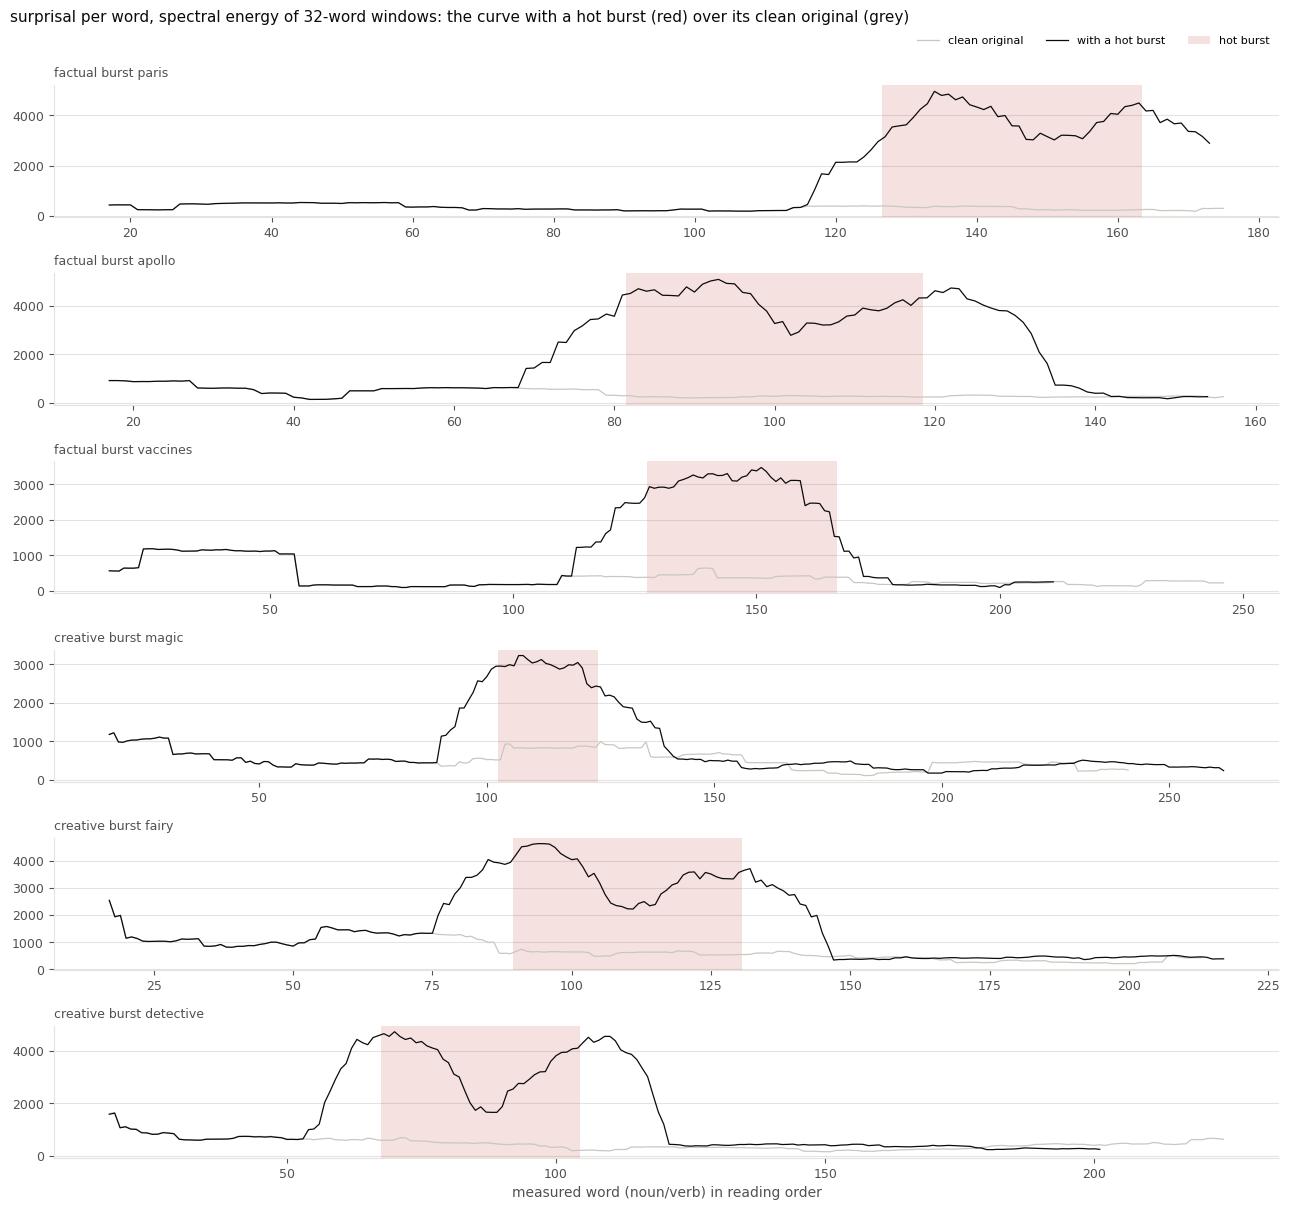

,signal,window,text,burst words,highest energy at word,inside the burst,"highest, burst text","highest, clean original"
0,"GloVe distance, top 5 guesses",16,factual_burst_paris,127-163,56,False,1.8,1.8
1,"GloVe distance, top 5 guesses",16,factual_burst_apollo,82-118,34,False,1.4,2.0
2,"GloVe distance, top 5 guesses",16,factual_burst_vaccines,128-166,132,True,1.6,1.7
3,"GloVe distance, top 5 guesses",16,creative_burst_magic,103-124,184,False,3.0,4.8
4,"GloVe distance, top 5 guesses",16,creative_burst_fairy,90-130,33,False,2.8,2.8
5,"GloVe distance, top 5 guesses",16,creative_burst_detective,68-104,198,False,3.3,2.7
6,"GloVe distance, top 5 guesses",32,factual_burst_paris,127-163,65,False,6.1,6.1
7,"GloVe distance, top 5 guesses",32,factual_burst_apollo,82-118,27,False,5.0,5.5
8,"GloVe distance, top 5 guesses",32,factual_burst_vaccines,128-166,207,False,5.3,5.1
9,"GloVe distance, top 5 guesses",32,creative_burst_magic,103-124,244,False,9.5,16.4


In [5]:
where_rows = []
stacked = {}
for signal_key in EVOLVING_SIGNALS:
    signal = signal_by_key(signal_key)
    for window in FOURIER_WINDOWS:
        for _index, burst in bursts.iterrows():
            table = burst_words[burst["text"]]
            values, rows = curve_with_rows(table, signal.column)
            clean_values, _clean_rows = curve_with_rows(clean_words[burst["clean original"]], signal.column)
            first = int(np.searchsorted(rows, first_row_from_char(table, int(burst["burst start char"]))))
            after_row = first_row_from_char(table, int(burst["burst end char"]))
            if after_row is None:
                last = len(rows) - 1
            else:
                last = int(np.searchsorted(rows, after_row)) - 1
            energy = window_energy(values, window)
            clean_energy = window_energy(clean_values, window)
            peak = int(np.nanargmax(energy))
            where_rows.append({"signal": signal.name, "window": window, "text": burst["text"],
                               "burst words": f"{first + 1}-{last + 1}", "highest energy at word": peak + 1,
                               "inside the burst": first <= peak <= last,
                               "highest, burst text": float(np.nanmax(energy)),
                               "highest, clean original": float(np.nanmax(clean_energy))})
            if signal_key == "surprisal_per_word" and window == max(FOURIER_WINDOWS):
                stacked.setdefault(signal.name, []).append(
                    {"name": burst["text"], "values": energy, "clean_values": clean_energy, "burst": (first, last),
                     "marks": []})
where = pd.DataFrame(where_rows)
where.to_csv(FOURIER_TABLES_DIR / "where.csv", index=False)
display(where.groupby(["signal", "window"], sort=False)["inside the burst"].sum()
        .rename("burst texts whose highest-energy window is inside the burst (of 6)"))

for signal_name, texts in stacked.items():
    fig = plot_bursts_stacked(f"{signal_name}, spectral energy of {max(FOURIER_WINDOWS)}-word windows", texts)
    save_to(fig, FOURIER_FIGURES_DIR, "where_surprisal.png")
    plt.show()
display(where.round(1))

## 4. What we can gather

**On human writing, rhythm alone tells the kinds apart about as well as the raw curves.** Best scores, each real
text labelled from the other 24: BOSSVS 23 of 25 (LCA height, top 3 guesses), 1-NN on spectra 21, clustering the
spectra 21, WEASEL 15; 1-NN with DTW on the raw curves (notebook 04) 22. With 48 signals and 4 methods tried on 25
texts, the single best score is partly luck; what holds is that the guess-meaning signals (LCA, GloVe) do best.
WEASEL is weak here: its default settings crash on so few texts, and the setting that runs (`quantile` bins) is
not suited to them.

**BOSSVS carries over to Qwen's texts better than DTW did.** On LCA it gives 5 of 6 clean texts the kind they were
written as (1-NN with DTW: 1 of 6). On GloVe (1 of 6) and surprisal (3 of 6: all called factual) it does not.

**A burst flattens the whole text's rhythm, clearly on surprisal.** In all 6 burst texts the fast share of the
surprisal spectrum drops below the clean original's (Paris 0.23 → 0.05, detective 0.38 → 0.06): the burst adds one
long rise and fall, which is slow-wave energy. LCA drops in 5 of 6, but by much less; GloVe in 4 of 6, in both
directions. So the whole-text spectrum flags a burst on surprisal, as agreed, and we zoomed in.

**Short windows then find it.** With 32-word windows, the window with the most spectral energy is inside the
burst in all 6 surprisal texts (5 of 6 with 16 words), at 1.8 to 9 times the clean original's highest. On LCA and
GloVe it is inside the burst in at most 1 of 6. By Parseval's theorem this window energy is how much the curve
swings inside the window, so this part is close to a moving spread of the curve.

**Caveats.** One burst per text; the same caveat as notebooks 03–04: surprisal sees hot writing, true or not.
